In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", "{:,.2f}".format)
sns.set_theme(style="whitegrid")

In [2]:
df = pd.read_csv('retail_orders_raw.csv')
df.head()

,order_id,order_date,product,category,region,sales_channel,payment_method,quantity,unit_price,discount_pct,customer_rating,order_status,sales_amount
0,ORD10001,2024-04-12,Kurta,Clothing,Central,Mobile App,UPI,2,"1,680.42",0.25,4.00,Delivered,"2,520.63"
1,ORD10002,2025-03-11,Smart Watch,Electronics,West,Store,Card,1,"4,167.93",0.15,3.60,Delivered,"3,542.74"
2,ORD10003,2024-09-27,Cookware Set,Home & Kitchen,Central,Mobile App,Cash on Delivery,1,"3,464.30",0.20,3.70,Delivered,"2,771.44"
3,ORD10004,2024-04-16,Desk Lamp,Home & Kitchen,Central,Website,Card,3,"3,662.57",0.10,3.30,Delivered,"9,888.94"
4,ORD10005,2024-03-12,Keyboard,Electronics,West,Marketplace,Cash on Delivery,3,"13,483.35",0.05,4.70,Cancelled,"38,427.55"


In [4]:
print("Dataset shape:", df.shape)
print("\\nColumn names:")
print(df.columns.tolist())
df.info()

Dataset shape: (2207, 13)
\nColumn names:
['order_id', 'order_date', 'product', 'category', 'region', 'sales_channel', 'payment_method', 'quantity', 'unit_price', 'discount_pct', 'customer_rating', 'order_status', 'sales_amount']
<class 'pandas.DataFrame'>
RangeIndex: 2207 entries, 0 to 2206
Data columns (total 13 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   order_id         2207 non-null   str    
 1   order_date       2207 non-null   str    
 2   product          2197 non-null   str    
 3   category         2207 non-null   str    
 4   region           2195 non-null   str    
 5   sales_channel    2207 non-null   str    
 6   payment_method   2207 non-null   str    
 7   quantity         2207 non-null   int64  
 8   unit_price       2207 non-null   float64
 9   discount_pct     2199 non-null   float64
 10  customer_rating  2189 non-null   float64
 11  order_status     2207 non-null   str    
 12  sales_amount     2207 non

In [5]:
df.describe(include="all").T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
order_id,2207,2200,ORD10318,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN
order_date,2207,682,2024-02-08,11,NaN,NaN,NaN,NaN,NaN,NaN,NaN
product,2197,25,Jeans,129,NaN,NaN,NaN,NaN,NaN,NaN,NaN
category,2207,14,Clothing,541,NaN,NaN,NaN,NaN,NaN,NaN,NaN
region,2195,5,South,481,NaN,NaN,NaN,NaN,NaN,NaN,NaN
sales_channel,2207,4,Mobile App,689,NaN,NaN,NaN,NaN,NaN,NaN,NaN
payment_method,2207,4,UPI,866,NaN,NaN,NaN,NaN,NaN,NaN,NaN
quantity,"2,207.00",NaN,NaN,NaN,1.91,1.11,-2.00,1.00,2.00,3.00,5.00
unit_price,"2,207.00",NaN,NaN,NaN,"3,240.84","3,215.54",-100.00,"1,120.96","2,213.53","4,019.16","14,940.03"
discount_pct,"2,199.00",NaN,NaN,NaN,0.10,0.07,0.00,0.05,0.10,0.15,0.25


In [6]:
print("Missing values by column:")
display(df.isna().sum().sort_values(ascending=False))

print("Duplicate rows:", df.duplicated().sum())

Missing values by column:


customer_rating    18
region             12
product            10
discount_pct        8
order_id            0
category            0
order_date          0
sales_channel       0
payment_method      0
unit_price          0
quantity            0
order_status        0
sales_amount        0
dtype: int64

Duplicate rows: 7


In [7]:
df = df.copy()

In [8]:
rows_before = len(df)
df = df.drop_duplicates().copy()
rows_after = len(df)

print("Rows before:", rows_before)
print("Rows after:", rows_after)
print("Exact duplicate rows removed:", rows_before - rows_after)

Rows before: 2207
Rows after: 2200
Exact duplicate rows removed: 7


In [9]:
text_columns = [
    "product", "category", "region",
    "sales_channel", "payment_method", "order_status"
]

for col in text_columns:
    df[col] = (
        df[col]
        .astype("string")
        .str.strip()
        .str.title()
    )

df[text_columns].head()

,product,category,region,sales_channel,payment_method,order_status
0,Kurta,Clothing,Central,Mobile App,Upi,Delivered
1,Smart Watch,Electronics,West,Store,Card,Delivered
2,Cookware Set,Home & Kitchen,Central,Mobile App,Cash On Delivery,Delivered
3,Desk Lamp,Home & Kitchen,Central,Website,Card,Delivered
4,Keyboard,Electronics,West,Marketplace,Cash On Delivery,Cancelled


In [10]:
df["order_date"] = pd.to_datetime(df["order_date"], errors="coerce")

In [11]:
numeric_columns = [
    "quantity", "unit_price", "discount_pct", "customer_rating"
]

for col in numeric_columns:
    df[col] = pd.to_numeric(df[col], errors="coerce")

print("Invalid/missing dates:", df["order_date"].isna().sum())
display(df[numeric_columns].dtypes)

Invalid/missing dates: 0


quantity             int64
unit_price         float64
discount_pct       float64
customer_rating    float64
dtype: object

In [12]:
invalid_quantity_or_price = (
    df["quantity"].isna()
    | df["unit_price"].isna()
    | (df["quantity"] <= 0)
    | (df["unit_price"] <= 0)
)

invalid_rows = df.loc[invalid_quantity_or_price].copy()
print("Rows flagged for invalid quantity/price:", len(invalid_rows))

# Keep only rows with positive quantity and positive unit price for the sales analysis.
df = df.loc[~invalid_quantity_or_price].copy()

print("Rows remaining:", len(df))

Rows flagged for invalid quantity/price: 14
Rows remaining: 2186


In [13]:
invalid_discount = (
    df["discount_pct"].notna()
    & ~df["discount_pct"].between(0, 1)
)

print("Discount values outside 0–1:", invalid_discount.sum())
display(df.loc[invalid_discount, ["order_id", "discount_pct"]].head(10))

# Do not silently reinterpret invalid discount values.
# Remove these records from this sales calculation until the source values are verified.
df = df.loc[~invalid_discount].copy()

df["discount_pct"] = df["discount_pct"].fillna(0)

Discount values outside 0–1: 0


,order_id,discount_pct


In [14]:
df["product"] = df["product"].fillna("Unknown Product")
df["category"] = df["category"].fillna("Unknown")
df["region"] = df["region"].fillna("Unknown")
df["sales_channel"] = df["sales_channel"].fillna("Unknown")
df["payment_method"] = df["payment_method"].fillna("Unknown")
df["order_status"] = df["order_status"].fillna("Unknown")

# Keep customer_rating missing for descriptive analysis.
# Median imputation can distort the rating distribution.

In [15]:
df["sales_amount"] = (
    df["quantity"] * df["unit_price"] * (1 - df["discount_pct"])
).round(2)

df[[
    "quantity", "unit_price", "discount_pct", "sales_amount"
]].head()

,quantity,unit_price,discount_pct,sales_amount
0,2,"1,680.42",0.25,"2,520.63"
1,1,"4,167.93",0.15,"3,542.74"
2,1,"3,464.30",0.20,"2,771.44"
3,3,"3,662.57",0.10,"9,888.94"
4,3,"13,483.35",0.05,"38,427.55"


In [16]:
print("Final dataset shape:", df.shape)
print("\\nMissing values:")
display(df.isna().sum())

print("Duplicate rows:", df.duplicated().sum())
print("Non-positive quantities:", (df["quantity"] <= 0).sum())
print("Non-positive unit prices:", (df["unit_price"] <= 0).sum())
print("Negative sales amounts:", (df["sales_amount"] < 0).sum())

df.info()

Final dataset shape: (2186, 13)
\nMissing values:


order_id            0
order_date          0
product             0
category            0
region              0
sales_channel       0
payment_method      0
quantity            0
unit_price          0
discount_pct        0
customer_rating    18
order_status        0
sales_amount        0
dtype: int64

Duplicate rows: 0
Non-positive quantities: 0
Non-positive unit prices: 0
Negative sales amounts: 0
<class 'pandas.DataFrame'>
Index: 2186 entries, 0 to 2199
Data columns (total 13 columns):
 #   Column           Non-Null Count  Dtype         
---  ------           --------------  -----         
 0   order_id         2186 non-null   str           
 1   order_date       2186 non-null   datetime64[us]
 2   product          2186 non-null   string        
 3   category         2186 non-null   string        
 4   region           2186 non-null   string        
 5   sales_channel    2186 non-null   string        
 6   payment_method   2186 non-null   string        
 7   quantity         2186 non-null   int64         
 8   unit_price       2186 non-null   float64       
 9   discount_pct     2186 non-null   float64       
 10  customer_rating  2168 non-null   float64       
 11  order_status     2186 non-null   string        
 12  sales_amount     2186 non-null   float64       
dtypes: datetim

In [17]:
df["year"] = df["order_date"].dt.year
df["month"] = df["order_date"].dt.month
df["month_name"] = df["order_date"].dt.strftime("%b")
df["year_month"] = df["order_date"].dt.to_period("M").astype("string")
df

,order_id,order_date,product,category,region,sales_channel,payment_method,quantity,unit_price,discount_pct,customer_rating,order_status,sales_amount,year,month,month_name,year_month
0,ORD10001,2024-04-12,Kurta,Clothing,Central,Mobile App,Upi,2,"1,680.42",0.25,4.00,Delivered,"2,520.63",2024,4,Apr,2024-04
1,ORD10002,2025-03-11,Smart Watch,Electronics,West,Store,Card,1,"4,167.93",0.15,3.60,Delivered,"3,542.74",2025,3,Mar,2025-03
2,ORD10003,2024-09-27,Cookware Set,Home & Kitchen,Central,Mobile App,Cash On Delivery,1,"3,464.30",0.20,3.70,Delivered,"2,771.44",2024,9,Sep,2024-09
3,ORD10004,2024-04-16,Desk Lamp,Home & Kitchen,Central,Website,Card,3,"3,662.57",0.10,3.30,Delivered,"9,888.94",2024,4,Apr,2024-04
4,ORD10005,2024-03-12,Keyboard,Electronics,West,Marketplace,Cash On Delivery,3,"13,483.35",0.05,4.70,Cancelled,"38,427.55",2024,3,Mar,2024-03
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2195,ORD12196,2025-04-27,Desk Lamp,Home & Kitchen,North,Website,Cash On Delivery,2,"1,551.35",0.00,4.20,Delivered,"3,102.70",2025,4,Apr,2025-04
2196,ORD12197,2024-04-17,Water Bottle,Home & Kitchen,North,Website,Card,1,846.47,0.10,4.90,Delivered,761.82,2024,4,Apr,2024-04
2197,ORD12198,2024-08-13,Bluetooth Speaker,Electronics,North,Website,Cash On Delivery,1,"7,492.08",0.20,4.40,Delivered,"5,993.66",2024,8,Aug,2024-08
2198,ORD12199,2025-11-03,Wireless Earbuds,Electronics,North,Mobile App,Card,1,"10,788.16",0.10,4.10,Returned,"9,709.34",2025,11,Nov,2025-11


In [18]:
df["order_value_band"] = pd.cut(
    df["sales_amount"],
    bins=[0, 1000, 5000, 10000, np.inf],
    labels=[
        "Under ₹1,000",
        "₹1,000–₹4,999",
        "₹5,000–₹9,999",
        "₹10,000 and above"
    ],
    right=False
)

df[[
    "order_date", "year", "month", "year_month",
    "sales_amount", "order_value_band"
]].head()

,order_date,year,month,year_month,sales_amount,order_value_band
0,2024-04-12,2024,4,2024-04,"2,520.63","₹1,000–₹4,999"
1,2025-03-11,2025,3,2025-03,"3,542.74","₹1,000–₹4,999"
2,2024-09-27,2024,9,2024-09,"2,771.44","₹1,000–₹4,999"
3,2024-04-16,2024,4,2024-04,"9,888.94","₹5,000–₹9,999"
4,2024-03-12,2024,3,2024-03,"38,427.55","₹10,000 and above"


In [19]:
total_rows = len(df)
total_orders = df["order_id"].nunique()
all_status_sales = df["sales_amount"].sum()

delivered_df = df[df["order_status"].eq("Delivered")].copy()
delivered_sales = delivered_df["sales_amount"].sum()
delivered_order_count = delivered_df["order_id"].nunique()

# Sum line items first, then average distinct order totals.
order_totals = (
    df.groupby("order_id", dropna=False)["sales_amount"]
      .sum()
)
overall_aov = order_totals.mean()

print(f"Rows in analysis: {total_rows:,}")
print(f"Distinct orders: {total_orders:,}")
print(f"Sales amount across all statuses: ₹{all_status_sales:,.2f}")
print(f"Delivered sales amount: ₹{delivered_sales:,.2f}")
print(f"Delivered distinct orders: {delivered_order_count:,}")
print(f"Average order value (all statuses): ₹{overall_aov:,.2f}")

print("Average customer rating (observed ratings only):",
      round(df["customer_rating"].mean(), 2))

Rows in analysis: 2,186
Distinct orders: 2,186
Sales amount across all statuses: ₹12,358,576.57
Delivered sales amount: ₹10,565,570.37
Delivered distinct orders: 1,869
Average order value (all statuses): ₹5,653.51
Average customer rating (observed ratings only): 3.97


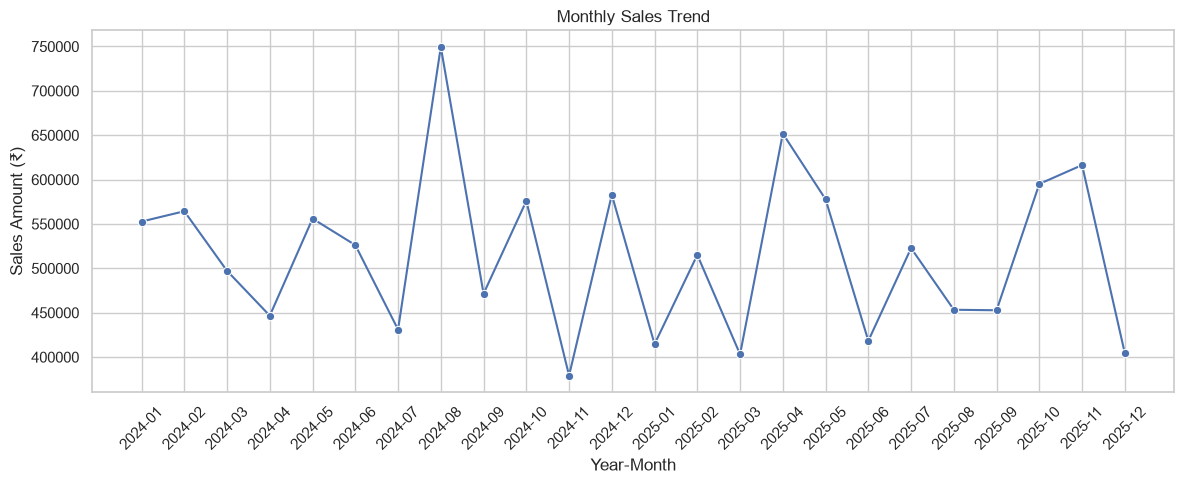

,year_month,sales_amount
0,2024-01,"552,729.20"
1,2024-02,"564,361.76"
2,2024-03,"497,136.76"
3,2024-04,"446,642.00"
4,2024-05,"556,045.12"
5,2024-06,"526,226.09"
6,2024-07,"431,017.26"
7,2024-08,"749,546.03"
8,2024-09,"471,410.35"
9,2024-10,"575,982.63"


In [20]:
monthly_sales = (
    df.dropna(subset=["order_date"])
      .groupby("year_month", as_index=False)["sales_amount"]
      .sum()
      .sort_values("year_month")
)

plt.figure(figsize=(12, 5))
sns.lineplot(
    data=monthly_sales,
    x="year_month",
    y="sales_amount",
    marker="o",
    errorbar=None
)
plt.title("Monthly Sales Trend")
plt.xlabel("Year-Month")
plt.ylabel("Sales Amount (₹)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

display(monthly_sales)

,region,sales_amount
3,South,"2,873,566.80"
2,North,"2,671,066.61"
0,Central,"2,355,124.48"
1,East,"2,242,415.48"
5,West,"2,143,957.58"
4,Unknown,"72,445.62"


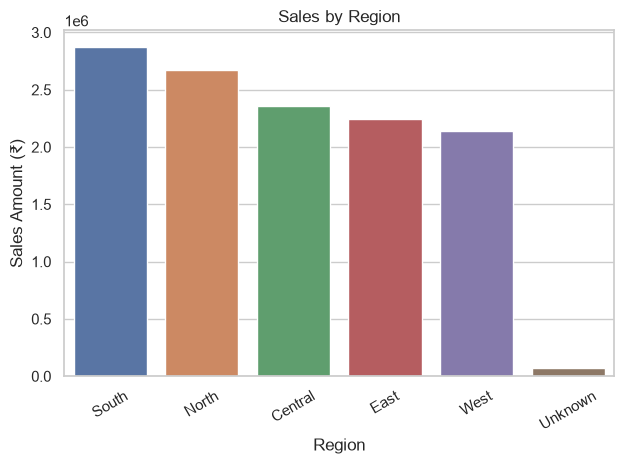

In [25]:
region_sales = (
    df.groupby("region", as_index=False)["sales_amount"]
      .sum()
      .sort_values("sales_amount", ascending=False)
)
display(region_sales)
#plt.figure(figsize=(7, 5))
sns.barplot(data=region_sales, x="region", y="sales_amount", hue="region", legend=False)
plt.title("Sales by Region")
plt.xlabel("Region")
plt.ylabel("Sales Amount (₹)")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

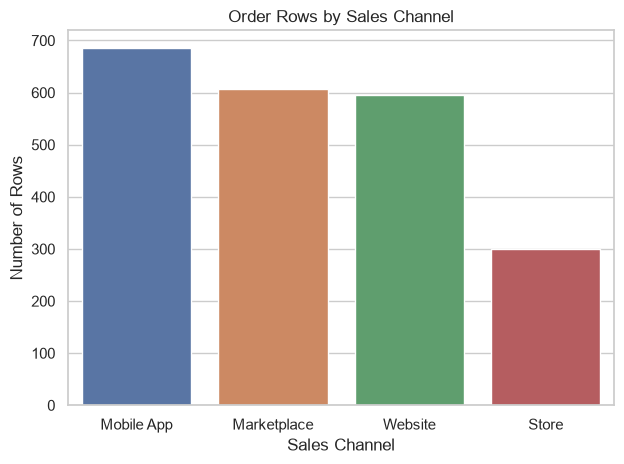

,sales_channel,row_count
0,Mobile App,685
1,Marketplace,606
2,Website,595
3,Store,300


In [27]:
channel_counts = df["sales_channel"].value_counts().rename_axis("sales_channel").reset_index(name="row_count")

#plt.figure(figsize=(8, 5))
sns.barplot(data=channel_counts, x="sales_channel", y="row_count", hue="sales_channel", legend=False)
plt.title("Order Rows by Sales Channel")
plt.xlabel("Sales Channel")
plt.ylabel("Number of Rows")
plt.tight_layout()
plt.show()

display(channel_counts)

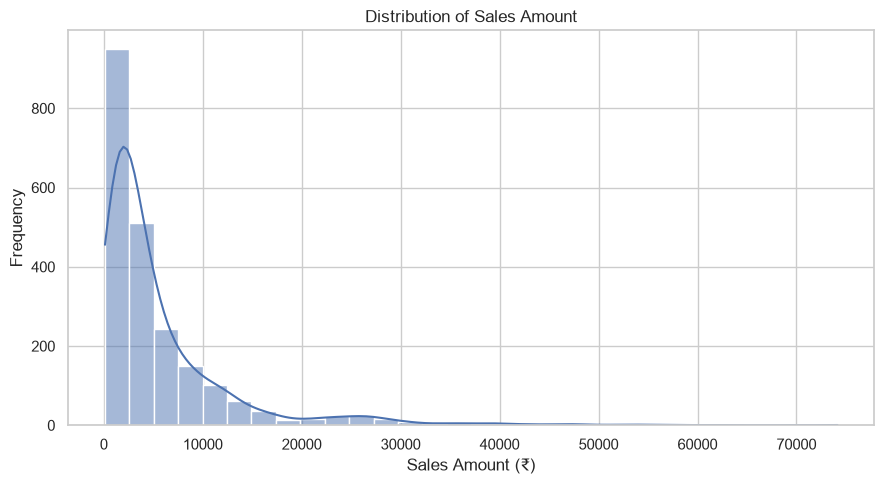

count    2,186.00
mean     5,653.51
std      7,309.98
min        119.08
25%      1,510.20
50%      3,076.34
75%      6,698.51
max     74,136.30
Name: sales_amount, dtype: float64

In [28]:
plt.figure(figsize=(9, 5))
sns.histplot(data=df, x="sales_amount", bins=30, kde=True)
plt.title("Distribution of Sales Amount")
plt.xlabel("Sales Amount (₹)")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()

display(df["sales_amount"].describe())

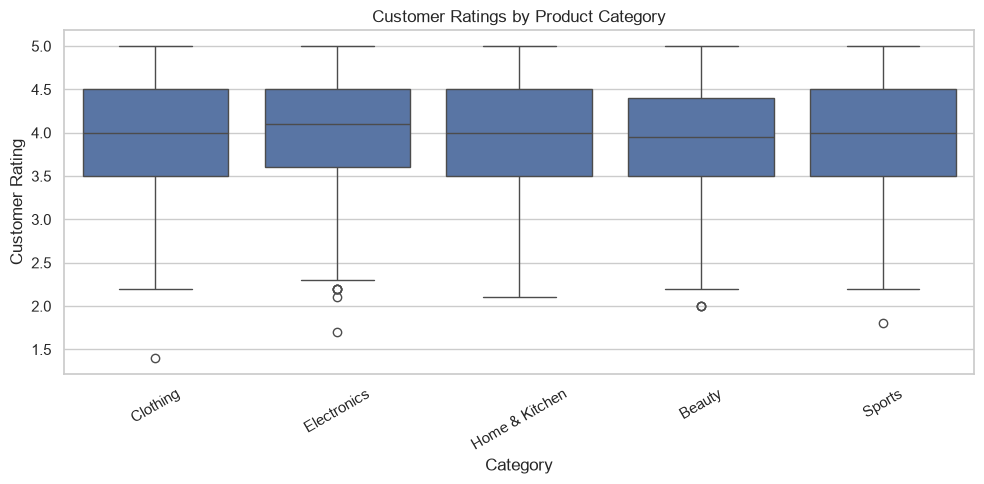

,count,mean,median
category,,,
Home & Kitchen,420,3.99,4.00
Electronics,464,3.99,4.10
Sports,336,3.96,4.00
Clothing,536,3.95,4.00
Beauty,412,3.95,3.95


In [29]:
rating_data = df.dropna(subset=["customer_rating"])

plt.figure(figsize=(10, 5))
sns.boxplot(data=rating_data, x="category", y="customer_rating")
plt.title("Customer Ratings by Product Category")
plt.xlabel("Category")
plt.ylabel("Customer Rating")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

display(
    rating_data.groupby("category")["customer_rating"]
               .agg(["count", "mean", "median"])
               .sort_values("mean", ascending=False)
)

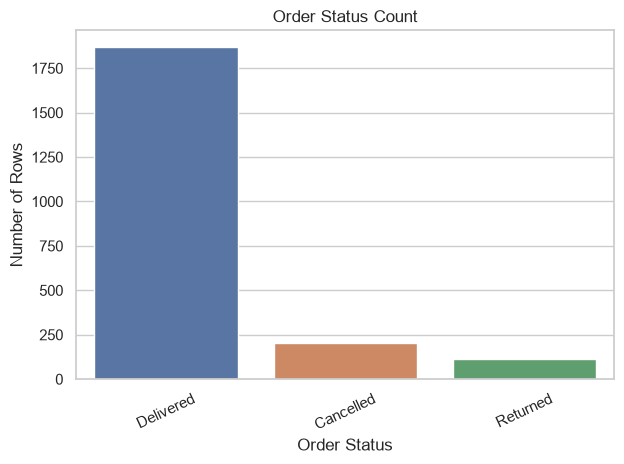

,row_count
order_status,
Delivered,1869
Cancelled,202
Returned,115


In [31]:
status_counts = df["order_status"].value_counts()

#plt.figure(figsize=(8, 5))
sns.barplot(x=status_counts.index, y=status_counts.values, hue=status_counts.index, legend=False)
plt.title("Order Status Count")
plt.xlabel("Order Status")
plt.ylabel("Number of Rows")
plt.xticks(rotation=25)
plt.tight_layout()
plt.show()

display(status_counts.to_frame("row_count"))

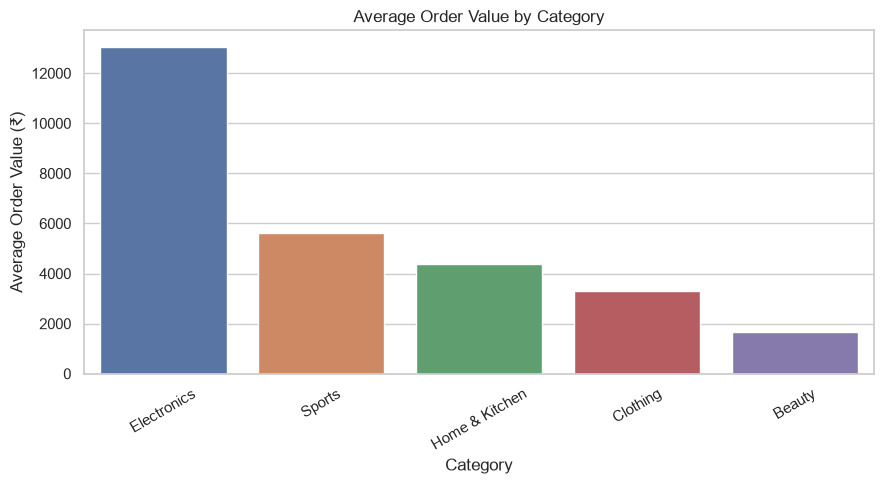

,category,average_order_value
2,Electronics,"13,054.38"
4,Sports,"5,637.73"
3,Home & Kitchen,"4,370.93"
1,Clothing,"3,312.30"
0,Beauty,"1,672.95"


In [32]:
# First calculate each order's value within each category.
order_category_totals = (
    df.groupby(["order_id", "category"], as_index=False)["sales_amount"]
      .sum()
)

category_aov = (
    order_category_totals.groupby("category", as_index=False)["sales_amount"]
                         .mean()
                         .rename(columns={"sales_amount": "average_order_value"})
                         .sort_values("average_order_value", ascending=False)
)

plt.figure(figsize=(9, 5))
sns.barplot(
    data=category_aov,
    x="category",
    y="average_order_value",
    hue="category",
    legend=False
)
plt.title("Average Order Value by Category")
plt.xlabel("Category")
plt.ylabel("Average Order Value (₹)")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

display(category_aov)

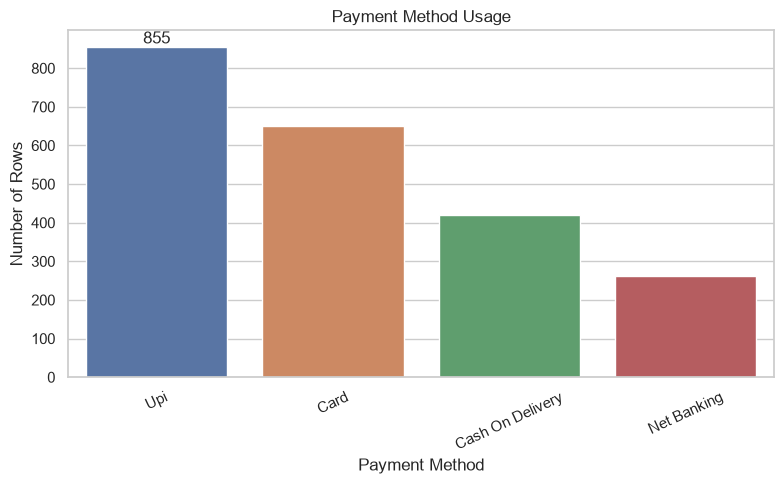

,row_count
payment_method,
Upi,855
Card,650
Cash On Delivery,420
Net Banking,261


In [33]:
payment_counts = df["payment_method"].value_counts()

plt.figure(figsize=(8, 5))
ax = sns.barplot(
    x=payment_counts.index,
    y=payment_counts.values,
    hue=payment_counts.index,
    legend=False
)
ax.bar_label(ax.containers[0])
plt.title("Payment Method Usage")
plt.xlabel("Payment Method")
plt.ylabel("Number of Rows")
plt.xticks(rotation=25)
plt.tight_layout()
plt.show()

display(payment_counts.to_frame("row_count"))

region,Central,East,North,South,Unknown,West
category,,,,,,
Beauty,"135,638.17","135,964.47","134,627.12","144,844.72",908.52,"143,965.27"
Clothing,"303,000.88","345,306.08","360,396.00","440,288.30","4,923.17","324,791.07"
Electronics,"1,127,262.40","1,069,646.13","1,402,465.09","1,472,479.30","52,247.51","985,349.12"
Home & Kitchen,"395,962.30","329,860.29","360,830.62","438,847.65","3,286.80","328,856.10"
Sports,"393,260.73","361,638.51","412,747.78","377,106.83","11,079.62","360,996.02"


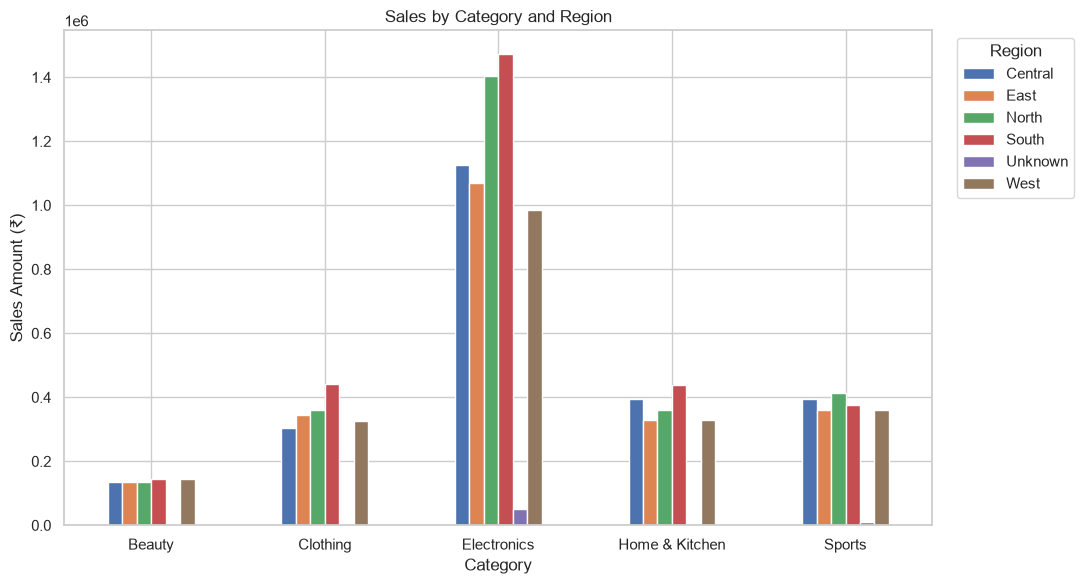

In [34]:
sales_pivot = pd.pivot_table(
    df,
    index="category",
    columns="region",
    values="sales_amount",
    aggfunc="sum",
    fill_value=0
)

display(sales_pivot)

sales_pivot.plot(kind="bar", figsize=(11, 6))
plt.title("Sales by Category and Region")
plt.xlabel("Category")
plt.ylabel("Sales Amount (₹)")
plt.xticks(rotation=0)
plt.legend(title="Region", bbox_to_anchor=(1.02, 1), loc="upper left")
plt.tight_layout()
plt.show()